<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 1. Aspectos generales — Modelo 5: Matriz Cruzada ABC / XYZ Segmentation

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Responsable: **Jack (Lead / Arquitecto Big Data)**.

Nota crítica de esquema: `../silver/merge_pyspark` **no tiene columna `quantity` ni stock**; cada fila representa **1 unidad vendida**. Procesamiento **100 % en Apache Spark nativo**:

- **ABC (Pareto de Ingresos):** participación acumulada de `SUM(price)` (`A <= 80%`, `B <= 95%`, `C > 95%`).
- **XYZ (Estabilidad de Demanda):** Coeficiente de Variación (`CV = stddev_pop / mean`) de unidades mensuales **sobre la grilla completa `article_id x mes`** (imputando `0` en meses sin venta para evitar sesgo): `X <= 0.50`, `Y <= 1.00`, `Z > 1.00`.
</div>

In [1]:
import os
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

In [2]:
spark = (
    SparkSession.builder
    .appName("HYM_Lab13_05_ABC_XYZ")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "4g")
    .config("spark.sql.shuffle.partitions", "50")
    .config("spark.memory.fraction", "0.8")
    .getOrCreate()
)

spark.sparkContext.setCheckpointDir("/tmp/spark_checkpoint")
spark

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 2. Rutas de capas

In [3]:
SILVER = "../silver"
GOLD   = "../gold"

os.makedirs(GOLD, exist_ok=True)

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 3. Lectura desde Silver y grilla completa artículo × mes

In [4]:
%%time
df_silver = (
    spark.read.parquet(f"{SILVER}/merge_pyspark")
    .select("article_id", "prod_name", "product_group_name", "department_name", "Fecha", "price")
    .filter(F.col("price").isNotNull() & (F.col("price") > 0))
    .withColumn("mes_venta", F.date_trunc("MONTH", F.col("Fecha")))
)

df_meses = df_silver.select("mes_venta").distinct()
n_meses = df_meses.count()

df_cat = df_silver.groupBy("article_id").agg(
    F.first("prod_name", ignorenulls=True).alias("prod_name"),
    F.first("product_group_name", ignorenulls=True).alias("product_group_name"),
    F.first("department_name", ignorenulls=True).alias("department_name"),
    F.sum("price").alias("ingreso_total"),
    F.count("*").alias("unidades_totales"),
)

df_ventas_mes = df_silver.groupBy("article_id", "mes_venta").agg(F.count("*").cast("double").alias("unidades_mes"))

# CrossJoin de catálogo x meses calendario para imputar 0 en meses sin venta
df_grilla = (
    df_cat.select("article_id")
    .crossJoin(F.broadcast(df_meses))
    .join(df_ventas_mes, on=["article_id", "mes_venta"], how="left")
    .fillna(0.0, subset=["unidades_mes"])
)
total_skus = int(df_cat.count())
print(f"Artículos únicos: {total_skus:,} | Meses calendario: {n_meses} | Celdas grilla: {total_skus * n_meses:,}")

Artículos únicos: 104,547 | Meses calendario: 25 | Celdas grilla: 2,613,675
CPU times: user 30.7 ms, sys: 15 ms, total: 45.6 ms
Wall time: 15.5 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 4. Clasificación ABC (Pareto ingresos) y XYZ (CV sobre grilla completa)

In [5]:
%%time
# XYZ por artículo sobre los N meses calendario completos
df_xyz = (
    df_grilla.groupBy("article_id")
    .agg(
        F.avg("unidades_mes").alias("media_mensual"),
        F.stddev_pop("unidades_mes").alias("std_mensual"),
    )
    .withColumn(
        "cv_demanda",
        F.when(F.col("media_mensual") > 0, F.col("std_mensual") / F.col("media_mensual")).otherwise(F.lit(99.0)),
    )
    .withColumn(
        "clase_xyz",
        F.when(F.col("cv_demanda") <= 0.50, "X")
         .when(F.col("cv_demanda") <= 1.00, "Y")
         .otherwise("Z"),
    )
)

# ABC por participación acumulada de ingreso_total (blindaje float ante Decimal)
ingreso_global = float(df_cat.agg(F.sum("ingreso_total")).collect()[0][0])
w_abc = Window.orderBy(F.col("ingreso_total").desc()).rowsBetween(Window.unboundedPreceding, 0)

df_abc_xyz = (
    df_cat
    .withColumn("pct_ingreso_acum", F.sum("ingreso_total").over(w_abc) / F.lit(ingreso_global))
    .withColumn(
        "clase_abc",
        F.when(F.col("pct_ingreso_acum") <= 0.80, "A")
         .when(F.col("pct_ingreso_acum") <= 0.95, "B")
         .otherwise("C"),
    )
    .join(df_xyz, on="article_id", how="inner")
    .withColumn("matriz_abc_xyz", F.concat(F.col("clase_abc"), F.col("clase_xyz")))
).checkpoint()

matriz_res = (
    df_abc_xyz.groupBy("matriz_abc_xyz", "clase_abc", "clase_xyz")
    .agg(
        F.count("*").alias("skus"),
        F.round(F.count("*") * F.lit(100.0) / F.lit(total_skus), 2).alias("pct_skus"),
        F.sum("unidades_totales").alias("unidades"),
        F.round(F.sum("ingreso_total"), 2).alias("ingresos"),
        F.round(F.sum("ingreso_total") * F.lit(100.0) / F.lit(ingreso_global), 2).alias("pct_ingresos"),
        F.round(F.avg("cv_demanda"), 3).alias("cv_promedio"),
    )
    .orderBy("clase_abc", "clase_xyz")
)
matriz_res.show(12, truncate=False)

+--------------+---------+---------+-----+--------+--------+---------+------------+-----------+
|matriz_abc_xyz|clase_abc|clase_xyz|skus |pct_skus|unidades|ingresos |pct_ingresos|cv_promedio|
+--------------+---------+---------+-----+--------+--------+---------+------------+-----------+
|AX            |A        |X        |74   |0.07    |389256  |7163.79  |0.81        |0.42       |
|AY            |A        |Y        |844  |0.81    |2717603 |64097.83 |7.25        |0.801      |
|AZ            |A        |Z        |19511|18.66   |20586624|636445.11|71.94       |2.237      |
|BX            |B        |X        |21   |0.02    |23765   |132.68   |0.01        |0.454      |
|BY            |B        |Y        |458  |0.44    |208571  |3046.13  |0.34        |0.846      |
|BZ            |B        |Z        |20624|19.73   |5392204 |129526.61|14.64       |2.37       |
|CY            |C        |Y        |194  |0.19    |28495   |345.4    |0.04        |0.879      |
|CZ            |C        |Z        |6282

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 5. Heatmap 3×3 ABC / XYZ (Ingresos y Concentración de SKUs)

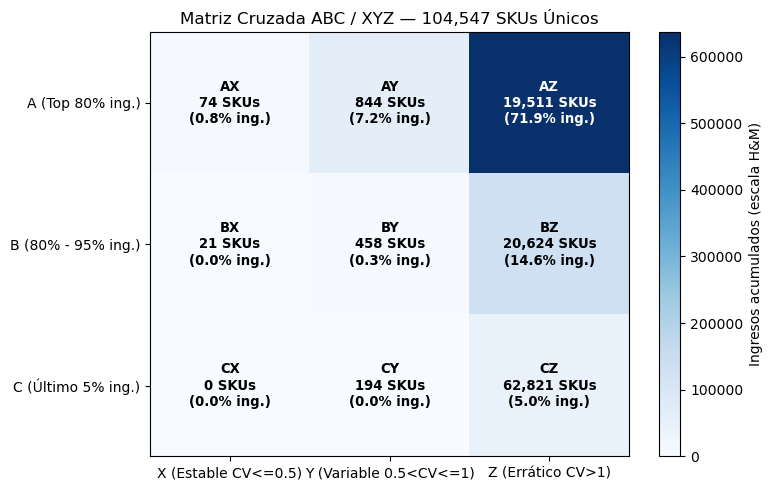

In [6]:
pdf_m = matriz_res.toPandas()
piv_ing = (
    pdf_m.pivot(index="clase_abc", columns="clase_xyz", values="ingresos")
    .reindex(index=["A", "B", "C"], columns=["X", "Y", "Z"]).fillna(0).astype(float)
)
piv_sku = (
    pdf_m.pivot(index="clase_abc", columns="clase_xyz", values="skus")
    .reindex(index=["A", "B", "C"], columns=["X", "Y", "Z"]).fillna(0).astype(float)
)
piv_pct = (
    pdf_m.pivot(index="clase_abc", columns="clase_xyz", values="pct_ingresos")
    .reindex(index=["A", "B", "C"], columns=["X", "Y", "Z"]).fillna(0).astype(float)
)

fig, ax = plt.subplots(figsize=(7.8, 5.0))
im = ax.imshow(piv_ing.values, cmap="Blues", aspect="auto")
fig.colorbar(im, ax=ax, label="Ingresos acumulados (escala H&M)")
ax.set_xticks(range(3)); ax.set_xticklabels(["X (Estable CV<=0.5)", "Y (Variable 0.5<CV<=1)", "Z (Errático CV>1)"])
ax.set_yticks(range(3)); ax.set_yticklabels(["A (Top 80% ing.)", "B (80% - 95% ing.)", "C (Último 5% ing.)"])

umbral = float(piv_ing.values.max()) * 0.50 if piv_ing.values.max() > 0 else 0.0
for i in range(3):
    for j in range(3):
        txt_color = "white" if piv_ing.values[i, j] > umbral else "black"
        ax.text(
            j, i,
            f"{piv_ing.index[i]}{piv_ing.columns[j]}\n{int(piv_sku.iloc[i, j]):,} SKUs\n({piv_pct.iloc[i, j]:.1f}% ing.)",
            ha="center", va="center", color=txt_color, fontweight="bold", fontsize=9.5,
        )

ax.set_title(f"Matriz Cruzada ABC / XYZ — {total_skus:,} SKUs Únicos")
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 6. Top 10 SKUs Estrella (AX) y Desglose por Grupo de Producto

Total SKUs en cuadrante estrella AX: 74
--- Top 10 SKUs AX por ingreso total ---
+----------+------------------------------+------------------+--------------+----------------+-------------+----------+
|article_id|prod_name                     |product_group_name|matriz_abc_xyz|unidades_totales|ingreso_total|cv_demanda|
+----------+------------------------------+------------------+--------------+----------------+-------------+----------+
|554450001 |Julia RW Skinny Denim TRS     |Garment Lower body|AX            |15245           |494.07       |0.383     |
|372860001 |7p Basic Shaftless            |Socks & Tights    |AX            |31718           |411.0        |0.204     |
|464297007 |Greta Thong Mynta Low 3p      |Underwear         |AX            |25025           |405.19       |0.356     |
|399256001 |Skinny Ankle R.W Brooklyn     |Garment Lower body|AX            |20242           |326.67       |0.398     |
|579541001 |Calista cardigan.             |Garment Upper body|AX            |15

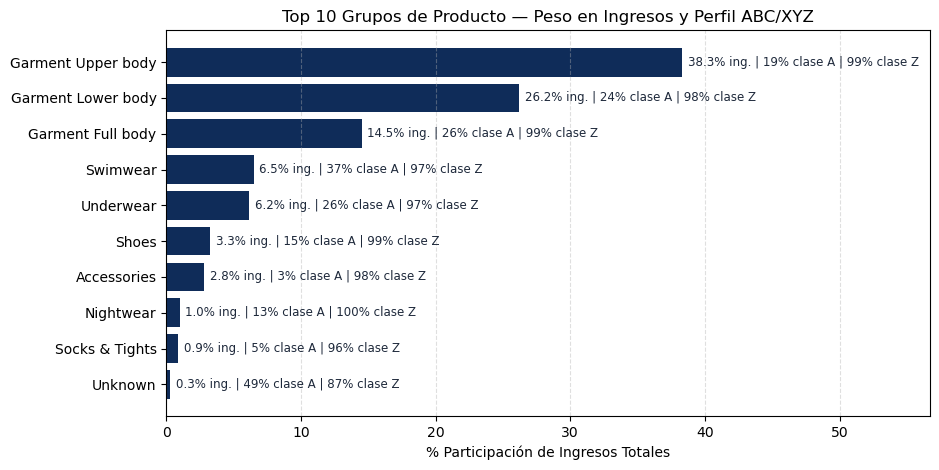

CPU times: user 266 ms, sys: 208 ms, total: 473 ms
Wall time: 996 ms


In [7]:
%%time
df_ax = df_abc_xyz.filter(F.col("matriz_abc_xyz") == "AX")
n_ax = df_ax.count()
print(f"Total SKUs en cuadrante estrella AX: {n_ax:,}")

cols_top = [
    "article_id", "prod_name", "product_group_name", "matriz_abc_xyz",
    "unidades_totales", "ingreso_total", "cv_demanda",
]
if n_ax >= 10:
    print("--- Top 10 SKUs AX por ingreso total ---")
    (
        df_ax.orderBy(F.col("ingreso_total").desc())
        .select(*cols_top[:-2], F.round("ingreso_total", 2).alias("ingreso_total"), F.round("cv_demanda", 3).alias("cv_demanda"))
        .show(10, truncate=False)
    )
else:
    print("Nota: por la alta rotación estacional (moda rápida H&M), el segmento AX tiene < 10 SKUs. Mostrando todos los AX y el Top 10 de clase A más estables:")
    if n_ax > 0:
        (
            df_ax.orderBy(F.col("ingreso_total").desc())
            .select(*cols_top[:-2], F.round("ingreso_total", 2).alias("ingreso_total"), F.round("cv_demanda", 3).alias("cv_demanda"))
            .show(n_ax, truncate=False)
        )
    (
        df_abc_xyz.filter(F.col("clase_abc") == "A")
        .orderBy(F.col("cv_demanda").asc(), F.col("ingreso_total").desc())
        .select(*cols_top[:-2], F.round("ingreso_total", 2).alias("ingreso_total"), F.round("cv_demanda", 3).alias("cv_demanda"))
        .show(10, truncate=False)
    )

df_grupos = (
    df_abc_xyz.groupBy("product_group_name")
    .agg(
        F.count("*").alias("skus"),
        F.sum(F.when(F.col("clase_abc") == "A", 1).otherwise(0)).alias("skus_A"),
        F.round(F.sum(F.when(F.col("clase_abc") == "A", 1).otherwise(0)) * F.lit(100.0) / F.count("*"), 1).alias("pct_A"),
        F.sum(F.when(F.col("clase_xyz") == "Z", 1).otherwise(0)).alias("skus_Z"),
        F.round(F.sum(F.when(F.col("clase_xyz") == "Z", 1).otherwise(0)) * F.lit(100.0) / F.count("*"), 1).alias("pct_Z"),
        F.round(F.sum("ingreso_total"), 2).alias("ingresos"),
        F.round(F.sum("ingreso_total") * F.lit(100.0) / F.lit(ingreso_global), 2).alias("pct_ingresos"),
    )
    .orderBy(F.col("ingresos").desc())
)
print("--- Top 10 Grupos de Producto por Ingresos ---")
df_grupos.show(10, truncate=False)

pdf_g = df_grupos.limit(10).toPandas()
pdf_g["pct_ingresos"] = pdf_g["pct_ingresos"].astype(float)
pdf_g["pct_A"] = pdf_g["pct_A"].astype(float)
pdf_g["pct_Z"] = pdf_g["pct_Z"].astype(float)
pdf_g = pdf_g.sort_values("pct_ingresos", ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.barh(pdf_g["product_group_name"], pdf_g["pct_ingresos"], color="#0F2C59")
for bar, (_, row) in zip(bars, pdf_g.iterrows()):
    ax.text(
        bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2,
        f"{row['pct_ingresos']:.1f}% ing. | {row['pct_A']:.0f}% clase A | {row['pct_Z']:.0f}% clase Z",
        va="center", fontsize=8.5, color="#1E293B",
    )
ax.set_xlim(0, float(pdf_g["pct_ingresos"].max()) * 1.48)
ax.set_xlabel("% Participación de Ingresos Totales")
ax.set_title("Top 10 Grupos de Producto — Peso en Ingresos y Perfil ABC/XYZ")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 7. Políticas Recomendadas de Inventario y Guardado en Capa Gold
</div>

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">
Reglas de decisión logística derivadas de la Matriz ABC / XYZ:
</div>

| Cuadrante | Perfil de Negocio | Política Recomendada de Reposición |
| :--- | :--- | :--- |
| **AX** | Alto ingreso (Pareto 80 %) + demanda estable | Reposición automática continua (JIT) y stock de seguridad bajo-fijo |
| **AY** | Alto ingreso + estacionalidad media | Pronóstico estacional semanal y stock de seguridad dinámico |
| **AZ** | Alto ingreso + demanda errática/colección cápsula | Compra bajo demanda, lotes acotados y monitoreo diario de quiebre |
| **BX / BY** | Ingreso medio (15 %) + demanda estable/variable | Revisión periódica quincenal y puntos de reorden automatizados |
| **BZ** | Ingreso medio + demanda errática | Reducir cobertura en tienda; centralizar stock en almacén regional |
| **CX / CY** | Cola larga (5 %) + rotación predecible | Consolidación de pedidos mensuales y reposición por mínimo económico |
| **CZ** | Cola larga + demanda altamente errática | Evaluar liquidación, canal exclusivamente online o descontinuación |


In [8]:
%%time
ruta_gold = f"{GOLD}/hym_abc_xyz"
df_abc_xyz.write.mode("overwrite").parquet(ruta_gold)

df_verif = spark.read.parquet(ruta_gold)
skus_gold = df_verif.count()
nulos_clase = df_verif.filter(
    F.col("clase_abc").isNull() | F.col("clase_xyz").isNull() | F.col("matriz_abc_xyz").isNull()
).count()

assert skus_gold > 0, "La salida Gold hym_abc_xyz resultó vacía"
assert nulos_clase == 0, f"Se detectaron {nulos_clase} filas sin clasificación ABC/XYZ"

print(f"Matriz ABC/XYZ guardada y auditada en {ruta_gold} | SKUs={skus_gold:,} | Nulos={nulos_clase}")
df_verif.printSchema()

Matriz ABC/XYZ guardada y auditada en ../gold/hym_abc_xyz | SKUs=104,547 | Nulos=0
root
 |-- article_id: long (nullable = true)
 |-- prod_name: string (nullable = true)
 |-- product_group_name: string (nullable = true)
 |-- department_name: string (nullable = true)
 |-- ingreso_total: double (nullable = true)
 |-- unidades_totales: long (nullable = true)
 |-- pct_ingreso_acum: double (nullable = true)
 |-- clase_abc: string (nullable = true)
 |-- media_mensual: double (nullable = true)
 |-- std_mensual: double (nullable = true)
 |-- cv_demanda: double (nullable = true)
 |-- clase_xyz: string (nullable = true)
 |-- matriz_abc_xyz: string (nullable = true)

CPU times: user 19.1 ms, sys: 1.43 ms, total: 20.5 ms
Wall time: 7.6 s


In [9]:
spark.stop()